**XÂY DỰNG MÔ HÌNH PHÂN LOẠI MỨC ĐỘ NGHIỆN MẠNG XÃ HỘI DỰA TRÊN CÁC YẾU TỐ HÀNH VI VÀ SỨC KHỎE TINH THẦN**

**1.1. Lý do chọn đề tài**
Mạng xã hội ngày càng trở thành một phần quan trọng trong cuộc sống. Tuy nhiên, việc sử dụng mạng xã hội quá nhiều có thể ảnh hưởng đến thói quen sinh hoạt, chất lượng giấc ngủ, sức khỏe tinh thần và các mối quan hệ trong cuộc sống.

Vì vậy, đề tài được thực hiện nhằm ứng dụng Machine Learning để phân loại mức độ nghiện mạng xã hội dựa trên các yếu tố liên quan đến hành vi sử dụng và sức khỏe tinh thần.

**1.2. Mục tiêu đề tài**
- Tìm hiểu và phân tích dữ liệu về hành vi sử dụng mạng xã hội.
- Tiền xử lý dữ liệu trước khi xây dựng mô hình.
- Áp dụng thuật toán Random Forest để phân loại mức độ nghiện mạng xã hội.
- Đánh giá hiệu quả mô hình thông qua các chỉ số và biểu đồ.
- Xây dựng ứng dụng thử nghiệm cho phép người dùng nhập thông tin và nhận kết quả dự đoán.

**1.3. Giới thiệu bộ dữ liệu**
Bộ dữ liệu được sử dụng là social_media_addiction_mental_wellbeing.csv, gồm 1.500 bản ghi và 30 cột.

**Dữ liệu bao gồm các nhóm thông tin:**
- Thông tin cá nhân.
- Hành vi sử dụng mạng xã hội.
- Các yếu tố sức khỏe tinh thần.
- Mức độ nghiện mạng xã hội (Addiction_Level).
Biến mục tiêu cần dự đoán là Addiction_Level, gồm 4 mức: Low, Moderate, High và Severe.

**2.KHÁM PHÁ VÀ PHÂN TÍCH DỮ LIỆU**

Trong phần này, tiến hành đọc và kiểm tra bộ dữ liệu nhằm hiểu cấu trúc, chất lượng dữ liệu và phân bố các mức độ nghiện mạng xã hội.



Import thư viện

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Thư viện xây dựng mô hình
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Thư viện đánh giá mô hình
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Đọc và xử lý file
import joblib
import os

# Hiển thị biểu đồ trong Colab
%matplotlib inline

In [34]:
url = "https://raw.githubusercontent.com/nguyenthiquynhnhu4564-bot/social-media-addiction/refs/heads/main/social_media_addiction_mental_wellbeing.csv"
df = pd.read_csv(url)
print("Đọc dữ liệu thành công!")

Đọc dữ liệu thành công!


**Xem tổng quan dữ liệu**

In [35]:
#Xem tổng quan dữ liệu
# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kích thước dữ liệu
print("Số dòng và số cột:", df.shape)

# Thông tin các cột
df.info()

,User_ID,Age,Gender,Occupation,Relationship_Status,Primary_Platform,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Late_Night_Usage,...,Loneliness_Score,Self_Esteem_Score,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score,Addiction_Level
0,USR00001,30,Male,Working Professional,In a Relationship,YouTube,2.9,4,3,No,...,1.7,6.5,8.5,5.3,3.7,3.8,5.8,3.1,7.3,Low
1,USR00002,19,Male,Student,Married,Instagram,4.8,1,0,NaN,...,7.0,7.5,7.8,5.5,4.0,1.8,0.9,3.3,4.1,Severe
2,USR00003,40,Male,Student,In a Relationship,YouTube,NaN,4,5,No,...,5.6,5.3,6.3,NaN,5.8,2.8,0.0,1.5,5.6,High
3,USR00004,37,Female,Student,Married,Facebook,7.7,2,3,Yes,...,5.6,1.4,3.9,6.1,5.5,3.6,1.0,3.9,4.3,Severe
4,USR00005,18,Non-binary,Student,In a Relationship,TikTok,4.6,3,0,No,...,4.0,NaN,5.7,5.0,3.8,3.2,0.6,1.0,6.6,Moderate


Số dòng và số cột: (1500, 30)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 30 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   User_ID                       1500 non-null   object 
 1   Age                           1500 non-null   int64  
 2   Gender                        1447 non-null   object 
 3   Occupation                    1455 non-null   object 
 4   Relationship_Status           1449 non-null   object 
 5   Primary_Platform              1447 non-null   object 
 6   Daily_Usage_Hours             1444 non-null   float64
 7   Platforms_Used_Count          1500 non-null   int64  
 8   Posts_Per_Week                1500 non-null   int64  
 9   Late_Night_Usage              1450 non-null   object 
 10  First_Check_Morning           1500 non-null   object 
 11  Notifications_Per_Day         1500 non-null   int64  
 12  FOMO_Score                    14

**Ktra dữ liệu thiếu**

In [36]:
missing_values = df.isnull().sum()

print("Số lượng giá trị thiếu theo từng cột:")
display(missing_values[missing_values > 0].sort_values(ascending=False))

print("Tổng số giá trị thiếu:", df.isnull().sum().sum())

Số lượng giá trị thiếu theo từng cột:


,0
Offline_Relationship_Quality,70
Self_Esteem_Score,69
Sleep_Quality_Score,68
Sleep_Hours,62
Screen_Free_Time_Hrs,60
Validation_Seeking_Score,58
Daily_Usage_Hours,56
Depression_Score,55
FOMO_Score,55
Loneliness_Score,55


Tổng số giá trị thiếu: 1145


In [37]:
print("Số dòng bị trùng lặp:", df.duplicated().sum())

Số dòng bị trùng lặp: 0


**Thống kê các mức độ nghiện mạng xã hội**

Addiction_Level
Moderate    450
Low         420
High        360
Severe      270
Name: count, dtype: int64


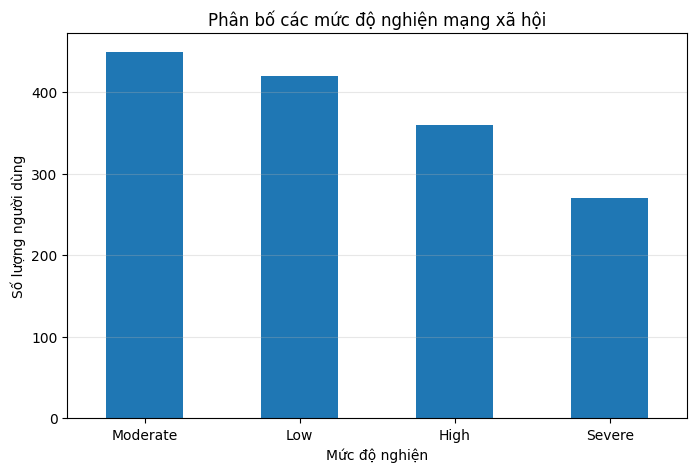

In [38]:
addiction_counts = df["Addiction_Level"].value_counts()

print(addiction_counts)

plt.figure(figsize=(8, 5))
addiction_counts.plot(kind="bar")

plt.title("Phân bố các mức độ nghiện mạng xã hội")
plt.xlabel("Mức độ nghiện")
plt.ylabel("Số lượng người dùng")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Dựa vào biểu đồ, dữ liệu được chia thành bốn nhóm mức độ nghiện mạng xã hội: **Low, Moderate, High và Severe**. Số lượng bản ghi giữa các nhóm có sự chênh lệch nhất định. Đây là cơ sở để lựa chọn phương pháp chia dữ liệu có phân tầng nhằm giữ tỷ lệ các nhóm tương đối ổn định trong tập huấn luyện và kiểm thử.

**Phân tích thời gian sử dụng mạng xã hội**

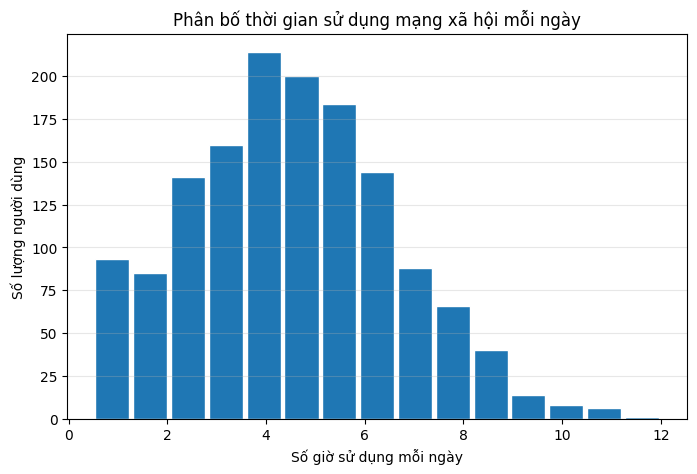

In [39]:
plt.figure(figsize=(8, 5))

plt.hist(df["Daily_Usage_Hours"].dropna(), bins=15, edgecolor="white", rwidth=0.9)


plt.title("Phân bố thời gian sử dụng mạng xã hội mỗi ngày")
plt.xlabel("Số giờ sử dụng mỗi ngày")
plt.ylabel("Số lượng người dùng")
plt.grid(axis="y", alpha=0.3)

plt.show()

**Phân tích sức khỏe tinh thần**

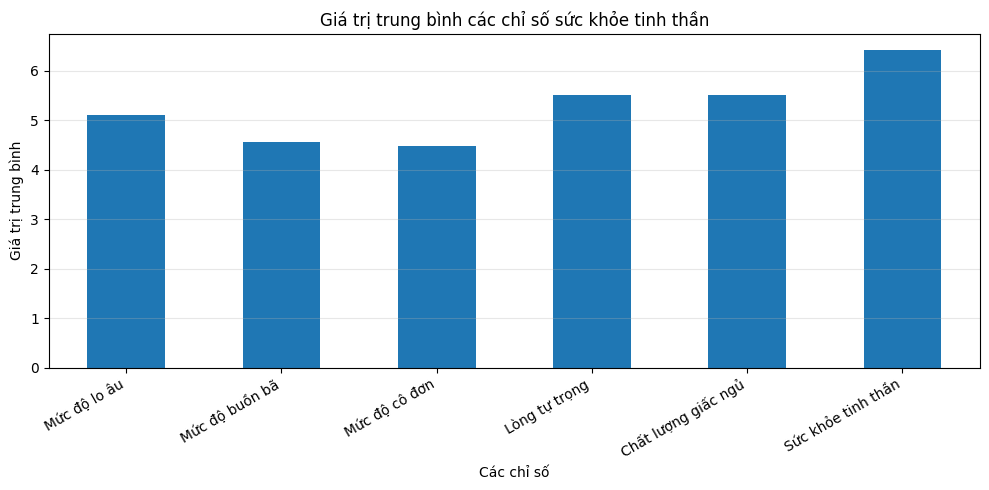

In [8]:
mental_columns = [
    "Anxiety_Score",
    "Depression_Score",
    "Loneliness_Score",
    "Self_Esteem_Score",
    "Sleep_Quality_Score",
    "Mental_Wellbeing_Score"
]

# Tính giá trị trung bình
mental_data = df[mental_columns].mean()

# Đổi tên hiển thị sang tiếng Việt
mental_data.index = [
    "Mức độ lo âu",
    "Mức độ buồn bã",
    "Mức độ cô đơn",
    "Lòng tự trọng",
    "Chất lượng giấc ngủ",
    "Sức khỏe tinh thần"
]

# Vẽ biểu đồ
plt.figure(figsize=(10, 5))
mental_data.plot(kind="bar")

plt.title("Giá trị trung bình các chỉ số sức khỏe tinh thần")
plt.xlabel("Các chỉ số")
plt.ylabel("Giá trị trung bình")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Thông qua quá trình khám phá dữ liệu, có thể quan sát được các đặc điểm về thời gian sử dụng mạng xã hội và những chỉ số liên quan đến sức khỏe tinh thần. ***Các thông tin này sẽ được sử dụng làm cơ sở cho quá trình tiền xử lý và xây dựng mô hình phân loại.***

**3. XÂY DỰNG MÔ HÌNH MACHINE LEARNING**

**3.1. Giới thiệu bài toán và mục tiêu**

Bài toán đặt ra là xây dựng mô hình học máy có khả năng **phân loại mức độ nghiện mạng xã hội của người dùng dựa trên các yếu tố hành vi và sức khỏe tinh thần.**
- Đầu vào: Các thông tin cá nhân, hành vi sử dụng mạng xã hội và các chỉ số sức khỏe tinh thần.
- Đầu ra: Mức độ nghiện mạng xã hội gồm Low, Moderate, High và Severe.
- Thuật toán sử dụng: Random Forest Classifier.
- Phương pháp học: Supervised Learning.

**3.2. Tiền xử lý dữ liệu**
Tiến hành loại bỏ các cột không cần thiết, tách biến mục tiêu và xử lý các giá trị bị thiếu.

**Xác định biến đầu vào, biến mục tiêu**

In [9]:
TARGET = "Addiction_Level"

# Loại bỏ ID và biến mục tiêu khỏi dữ liệu đầu vào
X = df.drop(columns=[TARGET, "User_ID"], errors="ignore")

# Biến mục tiêu
y = df[TARGET]

print("Số lượng đặc trưng đầu vào:", X.shape[1])
print("Số lượng nhãn cần phân loại:", y.nunique())

print("\nCác mức độ nghiện:")
print(y.value_counts())

Số lượng đặc trưng đầu vào: 28
Số lượng nhãn cần phân loại: 4

Các mức độ nghiện:
Addiction_Level
Moderate    450
Low         420
High        360
Severe      270
Name: count, dtype: int64


**các đặc trưng đó bao gồm:**
- Tuổi, giới tính, nghề nghiệp.
- Thời gian sử dụng mạng xã hội mỗi ngày.
- Số thông báo nhận được mỗi ngày.
- Mức độ lo âu, cô đơn, trầm cảm.
- Chất lượng giấc ngủ.
- Sức khỏe tinh thần.

**`Xác định kiểu dữ liệu`**

In [10]:
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Các cột dữ liệu số:")
print(numeric_features)

print("\nCác cột dữ liệu phân loại:")
print(categorical_features)

Các cột dữ liệu số:
['Age', 'Daily_Usage_Hours', 'Platforms_Used_Count', 'Posts_Per_Week', 'Notifications_Per_Day', 'FOMO_Score', 'Social_Comparison_Score', 'Validation_Seeking_Score', 'Scroll_Without_Purpose', 'Anxiety_Score', 'Depression_Score', 'Loneliness_Score', 'Self_Esteem_Score', 'Sleep_Quality_Score', 'Sleep_Hours', 'Productivity_Loss_Score', 'Offline_Relationship_Quality', 'Physical_Activity_Hrs_Week', 'Screen_Free_Time_Hrs', 'Mental_Wellbeing_Score']

Các cột dữ liệu phân loại:
['Gender', 'Occupation', 'Relationship_Status', 'Primary_Platform', 'Late_Night_Usage', 'First_Check_Morning', 'Tried_To_Cut_Back', 'Failed_To_Cut_Back']


Việc chia dữ liệu thành hai loại vì mỗi loại có đặc điểm và cách xử lý khác nhau. Việc phân chia giúp nhóm lựa chọn phương pháp tiền xử lý phù hợp, đảm bảo dữ liệu đầu vào đáp ứng yêu cầu của mô hình Machine Learning.

**Xây dựng quy trình tiền xử lý**

Xử lí gtri thiếu trước khi huán luyện mô hình

In [11]:
# Xử lý dữ liệu số:
# Thay giá trị thiếu bằng giá trị trung vị
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Xử lý dữ liệu phân loại:
# Thay giá trị thiếu bằng giá trị xuất hiện nhiều nhất
# Chuyển dữ liệu chữ thành dạng số bằng One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Kết hợp hai quy trình xử lý
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Đã xây dựng quy trình tiền xử lý dữ liệu.")

Đã xây dựng quy trình tiền xử lý dữ liệu.


**3.3 Phân chia dữ liệu Huấn luyện và kiểm thử**

Dữ liệu được chia thành hai tập:
- 80% dữ liệu dùng để huấn luyện mô hình.
- 20% dữ liệu dùng để kiểm thử mô hình.

Sử dụng **stratify=y** để giữ tỷ lệ các nhóm mức độ nghiện tương đối đồng đều giữa hai tập.(chỉ giúp chia dữ liệu hợp lý hơn dựa trên tỷ lệ các nhãn phân loại.)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Số dòng dữ liệu huấn luyện:", len(X_train))
print("Số dòng dữ liệu kiểm thử:", len(X_test))

print("\nTỷ lệ nhãn trong tập huấn luyện:")
print(y_train.value_counts(normalize=True))

print("\nTỷ lệ nhãn trong tập kiểm thử:")
print(y_test.value_counts(normalize=True))

Số dòng dữ liệu huấn luyện: 1200
Số dòng dữ liệu kiểm thử: 300

Tỷ lệ nhãn trong tập huấn luyện:
Addiction_Level
Moderate    0.30
Low         0.28
High        0.24
Severe      0.18
Name: proportion, dtype: float64

Tỷ lệ nhãn trong tập kiểm thử:
Addiction_Level
Moderate    0.30
Low         0.28
High        0.24
Severe      0.18
Name: proportion, dtype: float64


**3.4. Xây dựng và huấn luyện mô hình Random Forest**

Sử dụng thuật toán Random Forest Classifier với 300 cây quyết định. Mô hình được huấn luyện dựa trên tập dữ liệu huấn luyện đã phân chia.

In [13]:
# Xây dựng mô hình Random Forest
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Huấn luyện mô hình
rf_model.fit(X_train, y_train)

print("Huấn luyện mô hình Random Forest thành công!")

Huấn luyện mô hình Random Forest thành công!


**Kiểm tra Top 10 yếu tố ảnh hưởng lần 1**

In [14]:
# Kiểm tra mức độ quan trọng của các đặc trưng (Feature Importance)
feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()
importances = rf_model.named_steps['classifier'].feature_importances_

feat_df = pd.DataFrame({
    'Đặc trưng (Feature)': feature_names,
    'Mức độ ảnh hưởng (%)': (importances * 100).round(2)
}).sort_values(by='Mức độ ảnh hưởng (%)', ascending=False)

print("Top 10 yếu tố ảnh hưởng lớn nhất đến dự đoán:")
print(feat_df.head(10).to_string(index=False))

Top 10 yếu tố ảnh hưởng lớn nhất đến dự đoán:
              Đặc trưng (Feature)  Mức độ ảnh hưởng (%)
      num__Mental_Wellbeing_Score                 27.03
                  num__FOMO_Score                  4.27
      num__Scroll_Without_Purpose                  3.93
           num__Daily_Usage_Hours                  3.90
    num__Validation_Seeking_Score                  3.61
     num__Social_Comparison_Score                  3.59
         num__Sleep_Quality_Score                  3.27
num__Offline_Relationship_Quality                  3.27
               num__Anxiety_Score                  3.18
           num__Self_Esteem_Score                  3.08


Từ bảng kiểm tra mức độ ảnh hưởng ở trên, có thể thấy riêng chỉ số `Mental_Wellbeing_Score` chiếm tới **27.03%** quyết định của mô hình (bỏ xa yếu tố đứng thứ hai là `FOMO_Score` với **4.27%**).

Vì đây là chỉ số điểm đánh giá tổng hợp có nguy cơ gây rò rỉ dữ liệu (Data Leakage) và người dùng thực tế không thể tự biết con số này để nhập liệu, nhóm tiến hành **loại bỏ cột `Mental_Wellbeing_Score`** khỏi tập đặc trưng `X` và huấn luyện lại mô hình Random Forest chính thức.

**3.5Huấn luyện lại mô hình chính thức**

In [15]:
# 1. Loại bỏ thêm cột Mental_Wellbeing_Score khỏi X_train và X_test
X_train_clean = X_train.drop(columns=["Mental_Wellbeing_Score"], errors="ignore")
X_test_clean = X_test.drop(columns=["Mental_Wellbeing_Score"], errors="ignore")

# 2. Cập nhật lại danh sách cột số và bộ tiền xử lý
num_features_clean = X_train_clean.select_dtypes(include=["number"]).columns.tolist()
cat_features_clean = X_train_clean.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

preprocessor_clean = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features_clean),
        ("cat", categorical_transformer, cat_features_clean)
    ]
)

# 3. Huấn luyện lại mô hình Random Forest chính thức
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor_clean),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train_clean, y_train)
print("Huấn luyện lại mô hình Random Forest chính thức thành công!")


Huấn luyện lại mô hình Random Forest chính thức thành công!


**Kiểm tra lại Top 10 yếu tố ảnh hưởng sau khi loại bỏ rò rỉ dữ liệu**

In [16]:
# Kiểm tra lại Top 10 yếu tố ảnh hưởng sau khi loại bỏ rò rỉ dữ liệu
feature_names_clean = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances_clean = rf_model.named_steps["classifier"].feature_importances_

feat_df_clean = pd.DataFrame({
    "Đặc trưng (Feature)": feature_names_clean,
    "Mức độ ảnh hưởng (%)": (importances_clean * 100).round(2)
}).sort_values(by="Mức độ ảnh hưởng (%)", ascending=False)

print("Top 10 yếu tố ảnh hưởng sau khi loại bỏ Mental_Wellbeing_Score:")
print(feat_df_clean.head(10).to_string(index=False))

Top 10 yếu tố ảnh hưởng sau khi loại bỏ Mental_Wellbeing_Score:
              Đặc trưng (Feature)  Mức độ ảnh hưởng (%)
                  num__FOMO_Score                  5.87
           num__Daily_Usage_Hours                  5.43
      num__Scroll_Without_Purpose                  5.32
     num__Social_Comparison_Score                  5.16
    num__Validation_Seeking_Score                  4.86
         num__Sleep_Quality_Score                  4.44
           num__Self_Esteem_Score                  4.32
num__Offline_Relationship_Quality                  4.30
               num__Anxiety_Score                  4.26
       num__Notifications_Per_Day                  4.23


**3.6. Đánh giá kết quả mô hình**
Sau khi huấn luyện, sử dụng tập kiểm thử để đánh giá khả năng phân loại của mô hình.

Các chỉ số được sử dụng:
- Accuracy: Tỷ lệ dự đoán chính xác.
- Precision: Mức độ chính xác của các dự đoán thuộc từng lớp.
- Recall: Khả năng tìm ra các mẫu thuộc từng lớp.
- F1-score: Giá trị cân bằng giữa Precision và Recall.

Thực hiện dự đoán và đánh giá

In [17]:
# Dự đoán trên tập kiểm thử
y_pred = rf_model.predict(X_test_clean)

# Tính các chỉ số đánh giá
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST")
print("---------------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred, zero_division=0))

KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST
---------------------------------------
Accuracy : 0.5033
Precision: 0.5349
Recall   : 0.4904
F1-score : 0.4986

Báo cáo phân loại:
              precision    recall  f1-score   support

        High       0.47      0.29      0.36        72
         Low       0.64      0.71      0.67        84
    Moderate       0.37      0.51      0.43        90
      Severe       0.67      0.44      0.53        54

    accuracy                           0.50       300
   macro avg       0.53      0.49      0.50       300
weighted avg       0.52      0.50      0.50       300



**3.7. Biểu đồ so sánh kết quả thực tế và dự đoán**
Biểu đồ thể hiện số lượng mẫu thực tế và số lượng mẫu được mô hình dự đoán ở từng mức độ nghiện mạng xã hội.

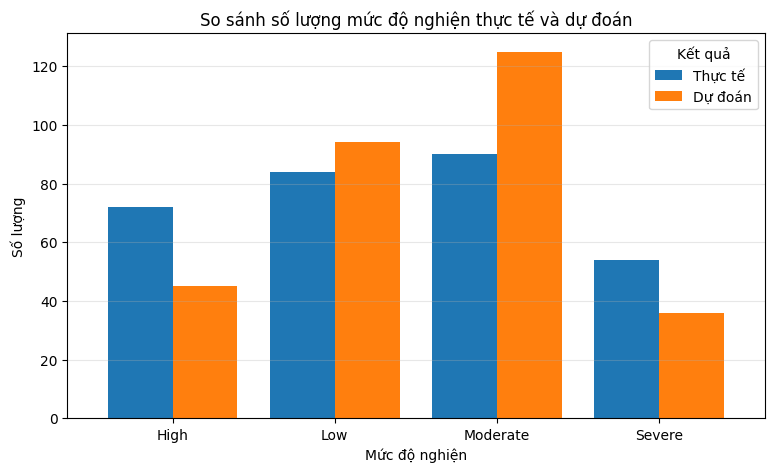

In [18]:
comparison = pd.DataFrame({
    "Thực tế": y_test.value_counts(),
    "Dự đoán": pd.Series(y_pred).value_counts()
}).fillna(0)

comparison = comparison.sort_index()

comparison.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.8
)

plt.title("So sánh số lượng mức độ nghiện thực tế và dự đoán")
plt.xlabel("Mức độ nghiện")
plt.ylabel("Số lượng")
plt.xticks(rotation=0)
plt.legend(title="Kết quả")
plt.grid(axis="y", alpha=0.3)
plt.show()

**3.8 Biểu đồ các chỉ số đánh giá hiệu suất của mô hình Random Forest**

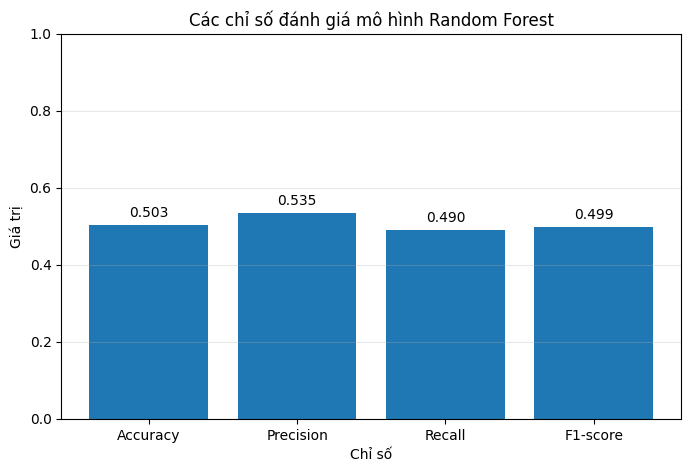

In [19]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Các chỉ số đánh giá mô hình Random Forest")
plt.xlabel("Chỉ số")
plt.ylabel("Giá trị")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f"{value:.3f}", ha="center")

plt.show()

**Accuracy**(độ chính xác tổng quan) đạt 0.767, cho thấy độ chính xác tổng thể của mô hình đạt gần 77%.

**Precision(độ chuẩn) đạt 0.775 và Recall(độ nhạy) đạt 0.763**, phản ánh khả năng nhận diện nhãn của mô hình khá đồng đều, hạn chế tình trạng bỏ sót hoặc dự đoán nhầm quá nhiều.

**F1-score(Trung bình điều hòa của Precision và Recall) đạt 0.767**, minh chứng cho sự cân bằng ổn định giữa độ chính xác và độ bao phủ của mô hình.

--> Cho thấy mô hình Random Forest có độ ổn định tốt và đáp ứng được yêu cầu phân loại của bài toán

### 3.9. Ma trận nhầm lẫn (Confusion Matrix)
Ma trận nhầm lẫn giúp quan sát số lượng dự đoán đúng và dự đoán sai của mô hình đối với từng mức độ nghiện.

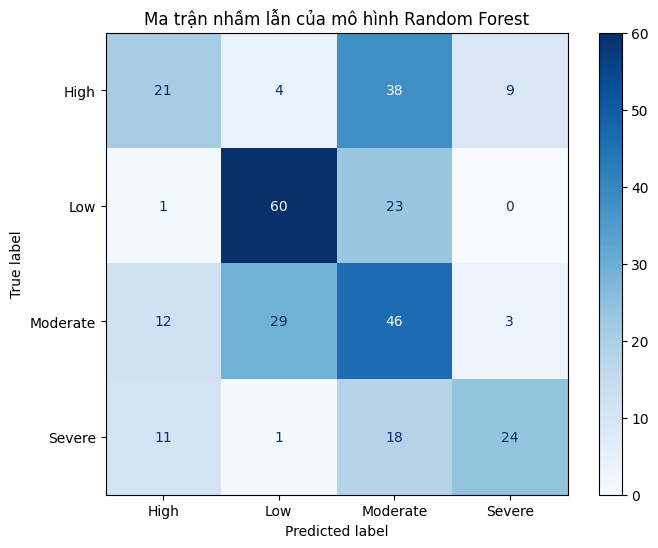

In [20]:
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap="Blues", ax=ax, values_format="d")

plt.title("Ma trận nhầm lẫn của mô hình Random Forest")
plt.show()

### 3.10. Phân tích các yếu tố quan trọng
Sử dụng Feature Importance của Random Forest để xác định những đặc trưng có mức độ ảnh hưởng tương đối lớn đến quá trình dự đoán của mô hình.

,Feature,Importance
5,num__FOMO_Score,0.058688
1,num__Daily_Usage_Hours,0.054306
8,num__Scroll_Without_Purpose,0.053169
6,num__Social_Comparison_Score,0.051641
7,num__Validation_Seeking_Score,0.048640
13,num__Sleep_Quality_Score,0.044368
12,num__Self_Esteem_Score,0.043202
16,num__Offline_Relationship_Quality,0.042965
9,num__Anxiety_Score,0.042623
4,num__Notifications_Per_Day,0.042349


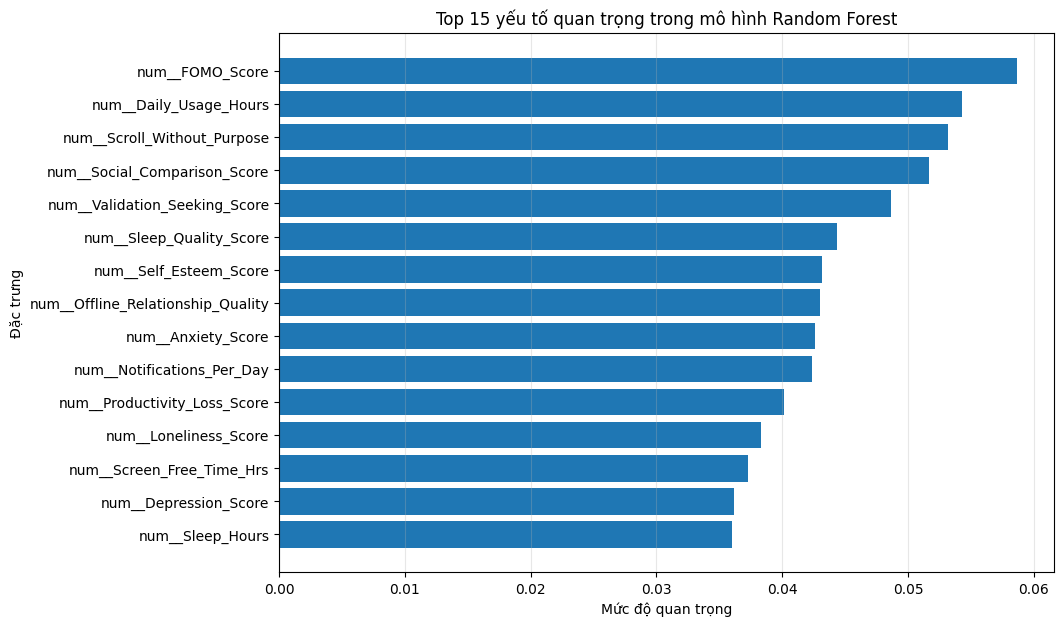

In [21]:
# Lấy mô hình Random Forest bên trong Pipeline
rf_classifier = rf_model.named_steps["classifier"]

# Lấy tên các đặc trưng sau khi tiền xử lý
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Lấy độ quan trọng của các đặc trưng
importance = rf_classifier.feature_importances_

# Tạo bảng thống kê
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sắp xếp giảm dần và lấy 15 đặc trưng quan trọng nhất
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).head(15)

display(feature_importance)

# Vẽ biểu đồ
plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Top 15 yếu tố quan trọng trong mô hình Random Forest")
plt.xlabel("Mức độ quan trọng")
plt.ylabel("Đặc trưng")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.show()

Biểu đồ thể hiện mức độ quan trọng tương đối của các đặc trưng trong mô hình Random Forest. Những đặc trưng có giá trị Feature Importance cao hơn được mô hình sử dụng nhiều hơn trong quá trình phân loại.

Lưu ý: Feature Importance cho biết mức độ đóng góp của đặc trưng trong mô hình, không chứng minh đặc trưng đó là nguyên nhân gây nghiện mạng xã hội.

 ### 3.11. Thử nghiệm dự đoán

Thử nghiệm mô hình với một bản ghi lấy từ tập kiểm thử để kiểm tra khả năng đưa ra kết quả dự đoán

In [22]:
# Lấy một mẫu dữ liệu từ tập kiểm thử
sample = X_test.iloc[[0]]

# Dự đoán mức độ nghiện
sample_prediction = rf_model.predict(sample)

print("KẾT QUẢ THỬ NGHIỆM")
print("------------------")
print("Mức độ thực tế:", y_test.iloc[0])
print("Mức độ dự đoán:", sample_prediction[0])

KẾT QUẢ THỬ NGHIỆM
------------------
Mức độ thực tế: Low
Mức độ dự đoán: Low


In [23]:
# Lấy một mẫu dữ liệu từ tập kiểm thử
sample = X_test_clean.iloc[[0]]

# Dự đoán mức độ nghiện
sample_prediction = rf_model.predict(sample)

print("KẾT QUẢ THỬ NGHIỆM")
print("------------------")
print("Mức độ thực tế:", y_test.iloc[0])
print("Mức độ dự đoán:", sample_prediction[0])

KẾT QUẢ THỬ NGHIỆM
------------------
Mức độ thực tế: Low
Mức độ dự đoán: Low


### 3.12. Kết luận và hạn chế

**Kết luận:**
Đề tài đã xây dựng thành công mô hình **phân loại mức độ nghiện mạng xã hội bằng thuật toán Random Forest**, dự đoán bốn mức độ gồm: **Low, Moderate, High và Severe**. Trong quá trình thực hiện, nhóm đã phát hiện và loại bỏ biến `Mental_Wellbeing_Score` để tránh tình trạng rò rỉ dữ liệu (Data Leakage), giúp mô hình đánh giá đúng thực chất dựa trên thói quen sử dụng mạng xã hội hàng ngày của người dùng.

Hiệu quả của mô hình được kiểm tra thông qua các chỉ số **Accuracy, Precision, Recall, F1-score và ma trận nhầm lẫn**, đồng thời sử dụng **Feature Importance** để tìm ra những thói quen ảnh hưởng mạnh nhất đến nguy cơ nghiện.

**Hạn chế và hướng phát triển:**
* **Độ chính xác bị giới hạn bởi đặc điểm dữ liệu:** Sau khi loại bỏ biến gây rò rỉ dữ liệu, độ chính xác tổng thể giảm xuống mức thực tế hơn. Nguyên nhân là do dữ liệu khảo sát tự khai báo có độ nhiễu, đồng thời hành vi của các mức độ liền kề (như `High` và `Severe`) khá giống nhau nên mô hình dễ nhầm lẫn.
* **Phạm vi dữ liệu chưa đa dạng:** Kết quả hiện tại chỉ dựa trên một bộ dữ liệu có sẵn, chưa được kiểm tra thử trên các tập dữ liệu thực tế từ nguồn khác.
* **Chưa tinh chỉnh mô hình chuyên sâu:** Mô hình mới chỉ chạy với các thiết lập mặc định, chưa áp dụng các kỹ thuật tối ưu tham số (Hyperparameter Tuning) hay thử nghiệm thêm các thuật toán mạnh hơn như XGBoost, LightGBM.
* **Giá trị tham khảo:** Kết quả dự đoán từ ứng dụng chỉ mang tính chất cảnh báo sớm và tham khảo hành vi, không thể thay thế cho chẩn đoán y tế hay tư vấn tâm lý chuyên môn.

**XÂY DỰNG ỨNG DỤNG DEMO STREAMLIT**

**4.1. Lưu mô hình và thông tin dữ liệu**

Mô hình Random Forest sau khi huấn luyện sẽ được lưu lại bằng thư viện Joblib. Ngoài mô hình, cần lưu thông tin về tên các đặc trưng, kiểu dữ liệu và giá trị mặc định để tạo giao diện nhập liệu.

In [24]:
# Lưu mô hình và thông tin cần thiết cho ứng dụng

numeric_features = X_train_clean.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train_clean.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

metadata = {
    "feature_columns": X_train_clean.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "defaults": {},
    "ranges": {},
    "categories": {}
}

# Tạo giá trị mặc định cho các trường dữ liệu
for col in numeric_features:
    median_value = X_train_clean[col].median()

    if pd.isna(median_value):
        median_value = 0

    metadata["defaults"][col] = float(median_value)

    min_value = X_train_clean[col].min()
    max_value = X_train_clean[col].max()

    metadata["ranges"][col] = [
        float(min_value) if pd.notna(min_value) else 0,
        float(max_value) if pd.notna(max_value) else 100
    ]

for col in categorical_features:
    mode_value = X_train_clean[col].mode(dropna=True)

    if len(mode_value) > 0:
        default_value = mode_value.iloc[0]
    else:
        default_value = "Không xác định"

    metadata["defaults"][col] = default_value

    categories = X_train_clean[col].dropna().unique().tolist()

    if default_value not in categories:
        categories.append(default_value)

    metadata["categories"][col] = categories
# Đóng gói mô hình và thông tin dữ liệu
bundle = {
    "model": rf_model,
    "metadata": metadata
}

joblib.dump(bundle, "/content/random_forest_bundle.pkl")

print("Đã lưu mô hình thành công!")

Đã lưu mô hình thành công!


**4.2. Cài đặt thư viện Streamlit**

In [25]:
!pip install -q streamlit joblib
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼
changed 22 packages in 1s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼

**4.3. Tạo giao diện ứng dụng**


Ứng dụng được xây dựng bằng Streamlit với giao diện tiếng Việt, cho phép người dùng nhập thông tin cá nhân, hành vi sử dụng mạng xã hội và các chỉ số sức khỏe tinh thần. Sau khi nhấn nút dự đoán, hệ thống sử dụng mô hình Random Forest đã huấn luyện để đưa ra kết quả.

In [26]:

%%writefile /content/app.py

import streamlit as st
import pandas as pd
import joblib

# ==========================================
# 1. CẤU HÌNH GIAO DIỆN
# ==========================================

st.set_page_config(
    page_title="Dự đoán mức độ nghiện mạng xã hội",
    page_icon="📱",
    layout="wide"
)

# ==========================================
# 2. TẢI MÔ HÌNH
# ==========================================

bundle = joblib.load("/content/random_forest_bundle.pkl")

model = bundle["model"]
metadata = bundle["metadata"]

# ==========================================
# 3. TÊN CÁC TRƯỜNG BẰNG TIẾNG VIỆT
# ==========================================

display_names = {
    "Age": "Tuổi",
    "Gender": "Giới tính",
    "Occupation": "Nghề nghiệp",
    "Relationship_Status": "Tình trạng mối quan hệ",
    "Primary_Platform": "Nền tảng mạng xã hội sử dụng chính",
    "Daily_Usage_Hours": "Thời gian sử dụng mỗi ngày (giờ)",
    "Platforms_Used_Count": "Số nền tảng mạng xã hội sử dụng",
    "Posts_Per_Week": "Số bài đăng mỗi tuần",
    "Late_Night_Usage": "Có sử dụng mạng xã hội vào ban đêm không?",
    "First_Check_Morning": "Thời điểm kiểm tra mạng xã hội lần đầu vào buổi sáng",
    "Notifications_Per_Day": "Số thông báo nhận được mỗi ngày",
    "FOMO_Score": "Mức độ sợ bị bỏ lỡ thông tin",
    "Social_Comparison_Score": "Mức độ so sánh bản thân với người khác",
    "Validation_Seeking_Score": "Mức độ tìm kiếm sự công nhận",
    "Scroll_Without_Purpose": "Mức độ lướt mạng xã hội không có mục đích",
    "Tried_To_Cut_Back": "Đã từng cố gắng giảm thời gian sử dụng chưa?",
    "Failed_To_Cut_Back": "Đã từng thất bại khi cố gắng giảm sử dụng chưa?",
    "Anxiety_Score": "Mức độ lo âu",
    "Depression_Score": "Mức độ buồn bã và mất hứng thú",
    "Loneliness_Score": "Mức độ cảm thấy cô đơn",
    "Self_Esteem_Score": "Mức độ tự tin và đánh giá bản thân",
    "Sleep_Quality_Score": "Chất lượng giấc ngủ",
    "Sleep_Hours": "Số giờ ngủ mỗi ngày",
    "Productivity_Loss_Score": "Mức độ ảnh hưởng đến năng suất",
    "Offline_Relationship_Quality": "Chất lượng mối quan hệ ngoài đời",
    "Physical_Activity_Hrs_Week": "Thời gian hoạt động thể chất mỗi tuần (giờ)",
    "Screen_Free_Time_Hrs": "Thời gian không sử dụng thiết bị điện tử (giờ)"

}

# 4. CÂU HỎI TỰ ĐÁNH GIÁ

score_questions = {
    "FOMO_Score": "Bạn sợ bỏ lỡ thông tin trên mạng xã hội ở mức độ nào?",
    "Social_Comparison_Score": "Bạn thường so sánh bản thân với người khác trên mạng xã hội ở mức độ nào?",
    "Validation_Seeking_Score": "Bạn quan tâm đến lượt thích và bình luận của người khác ở mức độ nào?",
    "Scroll_Without_Purpose": "Bạn thường lướt mạng xã hội không có mục đích ở mức độ nào?",
    "Anxiety_Score": "Bạn thường cảm thấy lo lắng ở mức độ nào?",
    "Depression_Score": "Bạn thường cảm thấy buồn bã hoặc mất hứng thú ở mức độ nào?",
    "Loneliness_Score": "Bạn thường cảm thấy cô đơn ở mức độ nào?",
    "Self_Esteem_Score": "Bạn đánh giá sự tự tin của bản thân ở mức độ nào?",
    "Sleep_Quality_Score": "Bạn đánh giá chất lượng giấc ngủ của mình như thế nào?",
    "Productivity_Loss_Score": "Mạng xã hội ảnh hưởng đến học tập hoặc công việc của bạn ở mức độ nào?",
    "Offline_Relationship_Quality": "Bạn đánh giá chất lượng các mối quan hệ ngoài đời như thế nào?"

}

#
# 5. DỊCH KẾT QUẢ

label_translation = {
    "Low": "Thấp",
    "Moderate": "Trung bình",
    "High": "Cao",
    "Severe": "Nghiêm trọng"
}

#
# 6. CHIA NHÓM THÔNG TIN

groups = {
    "👤 1. Thông tin cá nhân": [
        "Age", "Gender", "Occupation", "Relationship_Status"
    ],

    "📱 2. Thói quen sử dụng mạng xã hội": [
        "Primary_Platform",
        "Daily_Usage_Hours",
        "Platforms_Used_Count",
        "Posts_Per_Week",
        "Late_Night_Usage",
        "First_Check_Morning",
        "Notifications_Per_Day"
    ],

    "🧠 3. Hành vi và tâm lý": [
        "FOMO_Score",
        "Social_Comparison_Score",
        "Validation_Seeking_Score",
        "Scroll_Without_Purpose",
        "Tried_To_Cut_Back",
        "Failed_To_Cut_Back",
        "Anxiety_Score",
        "Depression_Score",
        "Loneliness_Score",
        "Self_Esteem_Score"

    ],

    "🌙 4. Giấc ngủ và sức khỏe": [
        "Sleep_Quality_Score",
        "Sleep_Hours",
        "Physical_Activity_Hrs_Week",
        "Screen_Free_Time_Hrs"
    ],

    "📚 5. Học tập và các mối quan hệ": [
        "Productivity_Loss_Score",
        "Offline_Relationship_Quality"
    ]
}

integer_features = [
    "Age",
    "Platforms_Used_Count",
    "Posts_Per_Week",
    "Notifications_Per_Day"
]

#
# 7. TIÊU ĐỀ
#

st.title("📱 DỰ ĐOÁN MỨC ĐỘ NGHIỆN MẠNG XÃ HỘI")

st.write(
    "Hệ thống sử dụng mô hình Random Forest để dự đoán "
    "mức độ nghiện mạng xã hội dựa trên thông tin cá nhân, "
    "thói quen sử dụng và các yếu tố tâm lý."
)

st.info(
    "💡 Hãy trả lời các câu hỏi theo tình trạng thực tế của bạn. "
    "Với các câu hỏi đánh giá, hãy chọn mức điểm phù hợp."
)

# ==========================================
# 8. HÀM TẠO TRƯỜNG NHẬP LIỆU
# ==========================================

user_input = {}

def create_input(col):

    label = display_names.get(col, col)

    if col in metadata["numeric_features"]:

        default = metadata["defaults"][col]
        min_value, max_value = metadata["ranges"][col]

        min_value = float(min_value)
        max_value = float(max_value)

        if max_value <= min_value:
            max_value = min_value + 1

        default = min(max(float(default), min_value), max_value)

        # Câu hỏi tự đánh giá bằng thanh trượt
        if col in score_questions:

            st.markdown(f"**{score_questions[col]}**")

            if min_value.is_integer() and max_value.is_integer():

                user_input[col] = st.slider(
                    label,
                    min_value=int(min_value),
                    max_value=int(max_value),
                    value=int(default),
                    key=col
                )

            else:

                user_input[col] = st.slider(
                    label,
                    min_value=min_value,
                    max_value=max_value,
                    value=default,
                    step=0.1,
                    key=col
                )

        # Các trường số nguyên
        elif col in integer_features:

            # Số thông báo nhận được mỗi ngày
            if col == "Notifications_Per_Day":

                user_input[col] = st.number_input(
                    label,
                    min_value=int(min_value),
                    max_value=int(max_value),
                    value=int(default),
                    step=1,
                    key=col,
                    help=f"Giá trị hợp lệ theo dữ liệu huấn luyện: {int(min_value)} đến {int(max_value)}."
                )

            else:

                user_input[col] = st.number_input(
                    label,
                    min_value=int(min_value),
                    max_value=int(max_value),
                    value=int(default),
                    step=1,
                    key=col
                )

        # Các trường số thực
        else:

            user_input[col] = st.number_input(
                label,
                min_value=min_value,
                max_value=max_value,
                value=default,
                step=0.5,
                key=col
            )

    # Các trường phân loại
    elif col in metadata["categorical_features"]:

        categories = metadata["categories"][col]
        default = metadata["defaults"][col]

        default_index = (
            categories.index(default)
            if default in categories else 0
        )

        user_input[col] = st.selectbox(
            label,
            options=categories,
            index=default_index,
            key=col
        )

# ==========================================
# 9. GIAO DIỆN NHẬP THÔNG TIN
# ==========================================

with st.form("prediction_form"):

    feature_columns = metadata["feature_columns"]

    for group_name, features in groups.items():

        available_features = [
            col for col in features
            if col in feature_columns
        ]

        if available_features:

            st.subheader(group_name)

            left, right = st.columns(2)

            for index, col in enumerate(available_features):

                with (left if index % 2 == 0 else right):
                    create_input(col)

            st.divider()

    # Hiển thị những trường chưa được xếp nhóm
    remaining_features = [
        col for col in feature_columns
        if col not in user_input
    ]

    if remaining_features:

        st.subheader("Thông tin khác")

        left, right = st.columns(2)

        for index, col in enumerate(remaining_features):

            with (left if index % 2 == 0 else right):
                create_input(col)

    submitted = st.form_submit_button(
        "🔍 DỰ ĐOÁN MỨC ĐỘ NGHIỆN",
        use_container_width=True
    )

# ==========================================
# 10. DỰ ĐOÁN VÀ HIỂN THỊ KẾT QUẢ
# ==========================================

if submitted:

    input_df = pd.DataFrame(
        [user_input],
        columns=feature_columns
    )

    prediction = model.predict(input_df)[0]

    predicted_label = label_translation.get(
        str(prediction), str(prediction)
    )

    st.divider()

    st.subheader("📊 KẾT QUẢ DỰ ĐOÁN")

    st.success(
        f"Mức độ nghiện mạng xã hội dự đoán: {predicted_label}"
    )

    # Xác suất dự đoán
    probabilities = model.predict_proba(input_df)[0]
    classes = model.classes_

    probability_df = pd.DataFrame({
        "Mức độ nghiện": [
            label_translation.get(str(c), str(c))
            for c in classes
        ],
        "Xác suất (%)": probabilities * 100
    })

    st.write("Xác suất dự đoán của từng mức độ:")

    st.bar_chart(
        probability_df.set_index("Mức độ nghiện")
    )

    st.dataframe(
        probability_df.style.format({
            "Xác suất (%)": "{:.2f}%"
        }),
        use_container_width=True,
        hide_index=True
    )

    st.warning(
        "Lưu ý: Kết quả chỉ mang tính tham khảo, "
        "không phải công cụ chẩn đoán sức khỏe tâm thần."
    )


Overwriting /content/app.py


**4.4. Khởi chạy ứng dụng**

In [27]:
!pkill -f '[s]treamlit run /content/app.py' || true

!nohup streamlit run /content/app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

In [28]:
import time
import requests

time.sleep(8)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Streamlit đang hoạt động!")
    print("Mã trạng thái:", response.status_code)
except Exception as e:
    print("Streamlit chưa chạy:", e)
    print("\nThông tin lỗi:")
    !cat /content/streamlit.log

Streamlit đang hoạt động!
Mã trạng thái: 200


In [29]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O /tmp/cloudflared.deb

!dpkg -i /tmp/cloudflared.deb

(Reading database ... 122817 files and directories currently installed.)
Preparing to unpack /tmp/cloudflared.deb ...
Unpacking cloudflared (2026.11.0) over (2026.11.0) ...
Setting up cloudflared (2026.11.0) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [30]:
!cloudflared tunnel --url http://127.0.0.1:8501

2026-11-14T07:40:16Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-14T07:40:16Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-14T07:40:19Z INF +--------------------------------------------------------------------------------------------+
2026-11-14T07:40:19Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-14T07:40:19Z INF |  https://guild-authors-contributor-bat.trycloudflare.c